# SAP-RPT-1.6 demo usage in a notebook 

This notebook illustrates how to quickly experiment with the deployed SAP-RPT model through the API endpoint. 

Below we outline a pragmatic, end-to-end workflow for applying SAP-RPT-1 to single-table data. 

The steps follow established data science process models (e.g., CRISP-DM / DASCPM), adapted to SAP-RPT-1's in-context learning paradigm, where no model training is required.

## 0. Setup GenAIHub credentials and import packages

Import the required libraries

In [1]:
# if needed, install some basic libraries
# !pip3 install scikit-learn
# !pip3 install seaborn
# !pip3 install dotenv


In [2]:
# Imports 
import os
import io
import json
from typing import List, Dict, Tuple, Optional



import pandas as pd
import numpy as np
import requests

import matplotlib.pyplot as plt
import seaborn as sns

from tqdm import tqdm
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_absolute_percentage_error, accuracy_score, f1_score



# Performance-friendly display
pd.set_option("display.max_columns", 200)
pd.set_option("display.width", 200)

/Users/d067487/Library/Python/3.9/lib/python/site-packages/urllib3/__init__.py:35: NotOpenSSLWarning: urllib3 v2 only supports OpenSSL 1.1.1+, currently the 'ssl' module is compiled with 'LibreSSL 2.8.3'. See: https://github.com/urllib3/urllib3/issues/3020
  warnings.warn(


### Import the `sap-rpt-1` API credentials

Below are two options to incorporate this into the notebook

### Option 1 - use `.env` file

Create a file `.env` at the root directory of this repo looking as follows:

```
AICORE_AUTH_URL=https://URL_TO_AUTHENTICATION/oauth/token
AICORE_CLIENT_ID=<Login field from the PassVault link above>
AICORE_CLIENT_SECRET=<Current password field from the Passvault link above>
```

The run the cell below to set these enviroment variables:

In [26]:
from dotenv import load_dotenv
load_dotenv()  

AICORE_AUTH_URL = os.getenv("AICORE_AUTH_URL")
AICORE_CLIENT_ID = os.getenv("YOUR_AICORE_CLIENT_SECRET")
AICORE_CLIENT_SECRET = os.getenv("AICORE_CLIENT_SECRET")

### Option 2 - specify the credentials directly in the notebook cell below

This is simpler but makes the credentials appear explicitly in the notebook. Fine for simply using the notebook but updated should not be pushed to the remote directory in this case. 

In [4]:

config_json = """
{
  "clientid": "YOUR_AICORE_CLIENT_ID",
  "clientsecret": "YOUR_AICORE_CLIENT_SECRET",
  "url": "AICORE_AUTH_URL",
  
}
"""

BASE_DEPLOYMENT_URL = "https://api.ai.prod.eu-central-1.aws.ml.hana.ondemand.com/v2/inference/deployments/"
DEPLOYMENTS = {
        "sap-rpt-1.6":"YOUR_RPT1.6_DEPLOYMENT_ID",
        "sap-rpt-1.6-large": "YOUR_RPT1.6-large_DEPLOYMENT_ID" #optional
}


cnfg = json.loads(config_json)

In [5]:
AICORE_AUTH_URL = cnfg['url']+'/oauth/token'
AICORE_CLIENT_ID = cnfg['clientid']
AICORE_CLIENT_SECRET = cnfg['clientsecret'] 
AICORE_RESOURCE_GROUP = 'default'




In [6]:
def select_model(model_name: str) -> Tuple[str, int]:
    if model_name in DEPLOYMENTS.keys():
        RPT_DEPLOYMENT_URL = BASE_DEPLOYMENT_URL + DEPLOYMENTS[model_name]
    else:
        raise ValueError("Invalid model name.")
    
    if model_name == "sap-rpt-1.6-large":
        MAX_CONTEXT_ROWS = 8_192
    else:
        MAX_CONTEXT_ROWS = 2_048
    
    return RPT_DEPLOYMENT_URL, MAX_CONTEXT_ROWS

In [7]:
RPT_DEPLOYMENT_URL, MAX_CONTEXT_ROWS = select_model('sap-rpt-1.6')

## Setup and test the authentication with AI Core using your credentials 

In [9]:
def get_access_token() -> str:
    assert all([AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET]), "Missing OAuth environment variables (AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET)"
    resp = requests.post(
        AICORE_AUTH_URL,
        data={
            "grant_type": "client_credentials",
            "client_id": AICORE_CLIENT_ID,
            "client_secret": AICORE_CLIENT_SECRET,
        },
        timeout=60,
    )
    resp.raise_for_status()
    return resp.json()["access_token"]
print("[check if valid access token was generated]: last 4 chars of my access token:", get_access_token()[-4:])

[check if valid access token was generated]: last 4 chars of my access token: gRvw


## Test RPT api with dummy data

- generate tabular data as pandas frames
- convert data tro parquet and send to API as POST request

In [10]:
#generate dummy data
context = pd.DataFrame({
    "row_id": [1, 2, 3, 4],
    "feature1": [10.0, 20.0, 30.0, 22.0],
    "feature2": [20.0, 15.0, 12.0, 17.2],
    "feature3": ["Lorem", "ipsum dolor", "sit", "amet"], 
    "my_target": ["A", "B", "A", "B"],
})

query = pd.DataFrame({
    "row_id": [5, 6],
    "feature1": [20.0, 11.0],
    "feature2": [16.0, 19.0],
    "feature3": ["random text", "dummy"],
    "my_target": [None, None],
})

table = pd.concat([context, query], ignore_index=True)

buffer = io.BytesIO()
table.to_parquet(buffer, index=False)
buffer.seek(0)

config = {
    "target_columns": [{
        "name": "my_target",
        "prediction_placeholder": None,
        "task_type": "classification",
        "top_k": 1,
    }],
    # explanation can be returned as well
    # "explanations": {
    #     "top_column_scores": 1,
    #     "top_relevant_context_rows": 2
    # }
}

#send the request
response = requests.post(
    RPT_DEPLOYMENT_URL+ '/predict_parquet',
    
    headers={
        "Authorization": f"Bearer {get_access_token()}",
        "ai-resource-group": AICORE_RESOURCE_GROUP,
    },
    files={
        "file": (
            "request.parquet",
            buffer,
            "application/vnd.apache.parquet",
        ),
    },
    data={
        "prediction_config": json.dumps(config),
        "index_column": "row_id",
        "parse_data_types": "false",
    },
    timeout=300,
)

response.raise_for_status()
predictions = response.json()
print(json.dumps(predictions, indent=2))



{
  "explanations": null,
  "id": "af6b9a41-a2e6-4c9b-a219-abbd46749ad3",
  "metadata": {
    "context_mode": "default",
    "num_columns": 5,
    "num_predictions": 2,
    "num_query_rows": 2,
    "num_rows": 6
  },
  "predictions": [
    {
      "my_target": [
        {
          "confidence": 0.94,
          "confidence_interval": null,
          "prediction": "B"
        }
      ],
      "row_id": 5
    },
    {
      "my_target": [
        {
          "confidence": 0.76,
          "confidence_interval": null,
          "prediction": "A"
        }
      ],
      "row_id": 6
    }
  ],
  "status": {
    "code": 0,
    "message": "ok"
  }
}


## 1. Select data to predict on
Load the data from local CSV file into a Pandas DataFrame that will serve as the basis for all subsequent steps. `used_cars_24.csv` is provided as en example for illustrative purposes - idea would be to experiment with an own local csv file.

In [11]:
# Load the CSV file
CSV_PATH = "used_cars_24.csv"

df = pd.read_csv(CSV_PATH)

assert len(df) > 0, "No rows loaded from CSV file!"
print(f"Loaded rows: {len(df)}")
print(f"Columns: {df.columns.tolist()}")
df.head()

Loaded rows: 5918
Columns: ['idx', 'Car Brand', 'Model', 'Price', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership', 'EMI (monthly)']


,idx,Car Brand,Model,Price,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,EMI (monthly)
0,0,Hyundai,EonERA PLUS,330399,2016,Hyderabad,Petrol,10674,Manual,2,7350
1,1,Maruti,Wagon R 1.0LXI,350199,2011,Hyderabad,Petrol,20979,Manual,1,7790
2,2,Maruti,Alto K10LXI,229199,2011,Hyderabad,Petrol,47330,Manual,2,5098
3,3,Maruti,RitzVXI BS IV,306399,2011,Hyderabad,Petrol,19662,Manual,1,6816
4,4,Tata,NanoTWIST XTA,208699,2015,Hyderabad,Petrol,11256,Automatic,1,4642


## 2. Define prediction target
Define the prediction target column that represent the business outcome you want to predict. For this used cars dataset, we'll predict the car price.

In [12]:
# Choose your target column 
TARGET_COLUMN = "Price" #"Fuel"

# Validate target column exists
assert TARGET_COLUMN in df.columns, f"Target column {TARGET_COLUMN} not found in dataset!"

print(f"Target column: {TARGET_COLUMN}")
print(f"Target distribution:\n{df[TARGET_COLUMN].value_counts().sort_index()}")
df[[TARGET_COLUMN]].head()

Target column: Price
Target distribution:
Price
91000      1
103599     1
105000     1
107000     1
107399     1
          ..
2724199    1
2976299    1
3495000    1
4100000    1
6500000    1
Name: count, Length: 4139, dtype: int64


,Price
0,330399
1,350199
2,229199
3,306399
4,208699


## 3. Define task type
Select the corresponding prediction task type you want to resolve with SAP-RPT-1:
- Regression for numeric targets (e.g., Price prediction)
- Classification for categorical targets (e.g., Ownership, Gear type)
Although SAP-RPT-1 can infer the task type automatically, explicitly setting it improves reproducibility and evaluation clarity.

Task type: regression


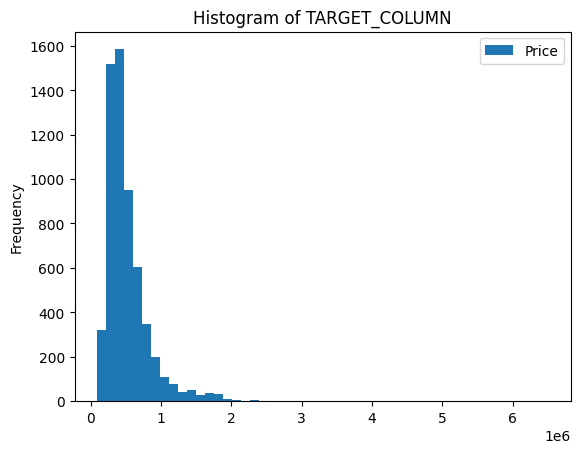

In [13]:
# Set task type explicitly: "regression" or "classification"
# For e.g. Price prediction, we use regression
TASK_TYPE = "regression" # "classification"

if TASK_TYPE == "regression":
    # Coerce target numeric where possible
    df[TARGET_COLUMN] = pd.to_numeric(df[TARGET_COLUMN], errors="coerce")
    df[[TARGET_COLUMN]].plot.hist(bins=50, title="Histogram of TARGET_COLUMN")
elif TASK_TYPE == "classification":
    # Treat as strings for classification
    df[TARGET_COLUMN] = df[TARGET_COLUMN].astype(str)
    df[TARGET_COLUMN].value_counts().sort_index().plot.bar(color='skyblue', alpha=0.75, title='Value Counts of TARGET_COLUMN')
else:
    raise ValueError(f"Unknown TASK_TYPE: {TASK_TYPE}")

print(f"Task type: {TASK_TYPE}")

## 4. Conduct leakage control
Remove any known leakers if present. 

(A column (feature) is allowed only if it is reliably known at the time of prediction. Any information that becomes available after the prediction moment is a leakage candidate and should be removed. Also other columns that contain information which would give trivial conclusion about the target and that are not available in real time scenarios, could be a leaker and results in unrealistically high performance scores.)

In [14]:
# Configure feature deny list (leakers) and drop them
# For price prediction, 'EMI (monthly)' is a leaker column - it has a direct linear relationship with the target variable 'Price'
LEAKER_COLUMNS: List[str] = ['EMI (monthly)']

# Drop leakers that exist in the dataset
existing_leakers = [col for col in LEAKER_COLUMNS if col in df.columns]
if existing_leakers:
    print(f"Dropping leaker columns: {existing_leakers}")
    df_clean = df.drop(columns=existing_leakers)
else:
    df_clean = df.copy()
    print("No leaker columns to drop")

print(f"Remaining columns: {df_clean.columns.tolist()}")
df_clean.head()

Dropping leaker columns: ['EMI (monthly)']
Remaining columns: ['idx', 'Car Brand', 'Model', 'Price', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership']


,idx,Car Brand,Model,Price,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership
0,0,Hyundai,EonERA PLUS,330399,2016,Hyderabad,Petrol,10674,Manual,2
1,1,Maruti,Wagon R 1.0LXI,350199,2011,Hyderabad,Petrol,20979,Manual,1
2,2,Maruti,Alto K10LXI,229199,2011,Hyderabad,Petrol,47330,Manual,2
3,3,Maruti,RitzVXI BS IV,306399,2011,Hyderabad,Petrol,19662,Manual,1
4,4,Tata,NanoTWIST XTA,208699,2015,Hyderabad,Petrol,11256,Automatic,1


## 5. Define baselines
Before evaluating SAP-RPT-1, define what "good performance" means in your specific context. Baselines provide critical reference points for interpreting results. We recommend defining at least:
- A naïve baseline, such as predicting the historical median or always predicting the majority class of the context rows.
- An expert-informed baseline, such as a simple rule or heuristic a domain expert would apply to predict the target.

In [15]:
def baseline_predictions(
    X_train: pd.DataFrame,
    y_train: pd.Series,
    X_test: pd.DataFrame,
    task_type: str,
) -> Dict[str, pd.Series]:
    results: Dict[str, pd.Series] = {}

    if task_type == "regression":
        # Naive: global median
        median_val = float(np.nanmedian(y_train.values))
        results["Naive-Median"] = pd.Series([median_val] * len(X_test), index=X_test.index, name=TARGET_COLUMN)
    elif task_type == "classification":
        # Naive: majority class
        majority = y_train.value_counts().idxmax()
        results["Naive-Majority"] = pd.Series([majority] * len(X_test), index=X_test.index, name=TARGET_COLUMN)
    else:
        raise ValueError(f"Unknown task type: {task_type}")

    return results

## 6. Define evaluation metrics
We recommend to pick evaluation metrics which reflect the business cost of errors. For regression, e.g., MAE/MAPE. For classification, e.g., accuracy.

In [16]:
def compute_metrics(y_true: pd.Series, y_pred: pd.Series, task_type: str) -> Dict[str, float]:
    if task_type == "regression":
        return {
            "MAE": float(mean_absolute_error(y_true=y_true, y_pred=y_pred)),
            "MAPE": float(mean_absolute_percentage_error(y_true=y_true, y_pred=y_pred)),
        }
    elif task_type == "classification":
        return {
            "Accuracy": float(accuracy_score(y_true=y_true, y_pred=y_pred)),
            "F1-Macro": float(f1_score(y_true=y_true, y_pred=y_pred, average="macro")),
        }
    else:
        raise ValueError(f"Unknown task type: {task_type}")

## 7. Define split strategy
Define how data is separated into context rows (used for in-context learning, also called training set for classical models) and evaluation rows (used for measuring performance, also called test set). 

If we have a dataset where time place an import role, we can split the data based on a feature (`SORTING_COLUMN` below) containing information about this time dimension. 

If this is not the case, we use a stratified split for classification and a random split for regression below. 


In [17]:
# Simple, readable split strategy
TEST_SIZE = 0.2
SORTING_COLUMN: Optional[str] = None  # set to a column (e.g., "Model Year") for time-based split

# Fill null with 0 to avoid problems with nulls in the models
df_model = df_clean.copy().fillna(0)

if SORTING_COLUMN:
    # Time-based split: sort then take last fraction as test
    assert SORTING_COLUMN in df.columns, f"SORTING_COLUMN {SORTING_COLUMN} not found in dataset!"
    df_sorted = df_model.sort_index().sort_values(by=[SORTING_COLUMN])
    n_test = max(1, int(len(df_sorted) * TEST_SIZE))
    df_train = df_sorted.iloc[:-n_test]
    df_test = df_sorted.iloc[-n_test:]
else:
    # Random or stratified
    stratify = df_model[TARGET_COLUMN] if TASK_TYPE == "classification" else None
    df_train, df_test = train_test_split(df_model, test_size=TEST_SIZE, random_state=42, stratify=stratify)

assert len(df_train) > 0, "No training rows after split!"
assert len(df_test) > 0, "No test rows after split!"

FEATURE_COLUMNS = [c for c in df_model.columns if c != TARGET_COLUMN]

X_train = df_train[FEATURE_COLUMNS].copy()
y_train = df_train[TARGET_COLUMN].copy()
X_test = df_test[FEATURE_COLUMNS].copy()
y_test = df_test[TARGET_COLUMN].copy()

print(f"Train: {len(X_train)} rows, Test: {len(X_test)} rows, Features: {len(FEATURE_COLUMNS)}, Target: {TARGET_COLUMN}")
print(f"Feature columns: {FEATURE_COLUMNS}")

Train: 4734 rows, Test: 1184 rows, Features: 9, Target: Price
Feature columns: ['idx', 'Car Brand', 'Model', 'Model Year', 'Location', 'Fuel', 'Driven (Kms)', 'Gear', 'Ownership']


## 8. Define context

`sap-rpt-1` is a transformer-based model just like LLMs. And just like LLMs can only handle context of a certain maximum length, `sap-rpt-1` has a limit in the number of context rows in can handle before running out of memory. 

- For `sap-rpt-1-small`, the maximum context size is set to 2048 rows
- For `sap-rpt-1-large`, the maximum context size is set to 65536 rows

Therefore, if the total number of context rows selected in the cell above (the training set) is larger than these limits, we need to select a subset of the training set to use as context. 

Below, this context selection is done at random. Internally, we experiment with other methods as well (e.g. stratified or similarity-based). 

In [18]:
#MAX_CONTEXT_ROWS was set above when choosing the model endpoint (e.g. 2048 for SAP-1.6)

# Random context sample resolved to X_context and y_context
X_context = X_train.sample(n=min(MAX_CONTEXT_ROWS, len(X_train)), random_state=42)
y_context = y_train.loc[X_context.index]

print(f"Context rows: {len(X_context)}")

Context rows: 2048


## 9. Construct the SAP-RPT-1.6 inference request through json
Build the SAP-RPT-1 API request table containing:
- Context rows with known target values
- Query rows where the target column is replaced with a prediction placeholder (e.g., [PREDICT])
- For larger amounts of prediction rows, e.g. above 128 rows you need to call the model in batches.

In [19]:
RPT_PREDICTION_PLACEHOLDER = "[PREDICT]"
MAX_QUERY_ROWS = 128


def to_python_type(val):
    """Convert numpy/pandas types to native Python types for JSON serialization."""
    if isinstance(val, (np.integer, np.floating)):
        return val.item()
    if isinstance(val, np.ndarray):
        return val.tolist()
    if isinstance(val, pd.Timestamp):
        return val.strftime('%Y-%m-%d')
    if pd.isna(val):
        return None
    return val


def build_rows(X_context: pd.DataFrame, y_context: pd.Series, X_query: pd.DataFrame) -> List[Dict]:
    rows: List[Dict] = []
    # Context rows with actual target
    for i, (_, row) in enumerate(X_context.iterrows()):
        rd = {k: to_python_type(v) for k, v in row.to_dict().items()}
        rd[TARGET_COLUMN] = to_python_type(y_context.iloc[i])
        rd["__row_idx__"] = f"1{i:06d}"
        rows.append(rd)
    # Query rows with placeholder
    for i, (_, row) in enumerate(X_query.iterrows()):
        rd = {k: to_python_type(v) for k, v in row.to_dict().items()}
        rd[TARGET_COLUMN] = RPT_PREDICTION_PLACEHOLDER
        rd["__row_idx__"] = f"2{i:06d}"
        rows.append(rd)
    return rows

## 10. Run inference and retrieve predictions
Call the deployed SAP-RPT endpoint, passing the data as a JSON payload. 

In [20]:
def get_access_token() -> str:
    assert all([AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET]), "Missing OAuth environment variables (AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET)"
    resp = requests.post(
        AICORE_AUTH_URL,
        data={
            "grant_type": "client_credentials",
            "client_id": AICORE_CLIENT_ID,
            "client_secret": AICORE_CLIENT_SECRET,
        },
        timeout=60,
    )
    resp.raise_for_status()
    return resp.json()["access_token"]


def call_rpt_predict(payload: Dict, access_token: str) -> Dict:
    assert RPT_DEPLOYMENT_URL, "RPT_DEPLOYMENT_URL must be set to call the API"
    url = f"{RPT_DEPLOYMENT_URL}/predict"
    headers = {
        "Content-Type": "application/json",
        "Authorization": f"Bearer {access_token}",
        "ai-resource-group": AICORE_RESOURCE_GROUP,
    }
    result = requests.post(url, headers=headers, data=json.dumps(payload), timeout=300).json()

    # Check for errors in response
    status_code = result["status"]["code"]
    status_message = result["status"]["message"]
    detail = result.get("detail", [])

    if status_code > 0:
        raise RuntimeError(
            f"Prediction failed with status code {status_code}: {status_message} (Details: {json.dumps(detail, indent=4)})"
        )

    return result


def extract_predictions(response: Dict, target_column: str) -> Tuple[List, List[float]]:
    preds = [row[target_column][0]["prediction"] for row in response.get("predictions", [])]
    confs = [row[target_column][0].get("confidence", 0.0) for row in response.get("predictions", [])]
    pred_intervals = [row[target_column][0].get("confidence_interval", 0.0) for row in response.get("predictions", [])]
    return preds, confs, pred_intervals


def run_rpt_in_batches(X_context: pd.DataFrame, y_context: pd.Series, X_eval: pd.DataFrame, task_type: str) -> Tuple[pd.Series, pd.Series]:
    access_token = get_access_token()

    # Always use batching (single batch if small enough)
    num_batches = (len(X_eval) + MAX_QUERY_ROWS - 1) // MAX_QUERY_ROWS
    print(f"Batching {len(X_eval)} test rows into {num_batches} batch(es) of max {MAX_QUERY_ROWS}...")
    preds_all: List = []
    confs_all: List[float] = []
    pred_intervals_all: List = []

    for start in tqdm(
        range(0, len(X_eval), MAX_QUERY_ROWS),
        total=num_batches,
        desc=f"Processing prediction batches over API [B={MAX_QUERY_ROWS}]",
    ):
        X_batch = X_eval.iloc[start : start + MAX_QUERY_ROWS]
        rows = build_rows(X_context=X_context, y_context=y_context, X_query=X_batch)
        payload = {
            "prediction_config": {
                "target_columns": [
                    {
                        "name": TARGET_COLUMN,
                        "prediction_placeholder": RPT_PREDICTION_PLACEHOLDER,
                        "task_type": task_type,
                    }
                ]
            },
            "index_column": "__row_idx__",
            "rows": rows,
        }

        response = call_rpt_predict(payload=payload, access_token=access_token)
        preds, confs, pred_intervals = extract_predictions(response=response, target_column=TARGET_COLUMN)
        preds_all.extend(preds)
        confs_all.extend(confs)
        pred_intervals_all.extend(pred_intervals)

    y_pred = pd.Series(preds_all, index=X_eval.index, name=TARGET_COLUMN)
    # Ensure numeric conversions for regression
    if task_type == "regression":
        y_pred = pd.to_numeric(y_pred, errors="coerce")
    conf_series = pd.Series(confs_all, index=X_eval.index, name="confidence")
    pred_intervals_series = pd.Series(pred_intervals_all, index=X_eval.index, name="pred_intervals")
    return y_pred, conf_series, pred_intervals_series

In [21]:
# Compute baselines (naive only)
baseline_preds = baseline_predictions(X_train=X_train, y_train=y_train, X_test=X_test, task_type=TASK_TYPE)

# Assert RPT creds and URL are set before calling API
assert AICORE_AUTH_URL and AICORE_CLIENT_ID and AICORE_CLIENT_SECRET and AICORE_RESOURCE_GROUP, (
    "All RPT credentials must be set in environment: AICORE_AUTH_URL, AICORE_CLIENT_ID, AICORE_CLIENT_SECRET, AICORE_RESOURCE_GROUP"
)
assert RPT_DEPLOYMENT_URL, "RPT_DEPLOYMENT_URL constant must be set to a valid endpoint"

# Call RPT (requires valid deployment + credentials)
y_pred_rpt, rpt_conf, rpt_pred_intervals_series = run_rpt_in_batches(
    X_context=X_context,
    y_context=y_context,
    X_eval=X_test,
    task_type=TASK_TYPE,
)
rpt_pred_intervals = pd.DataFrame(rpt_pred_intervals_series.tolist(), columns=['lower_bound', 'upper_bound'], index=rpt_pred_intervals_series.index)

# Collect metrics
all_metrics: Dict[str, Dict[str, float]] = {}
for name, y_pred_baseline in baseline_preds.items():
    all_metrics[name] = compute_metrics(y_true=y_test, y_pred=y_pred_baseline, task_type=TASK_TYPE)

all_metrics["RPT-1"] = compute_metrics(y_true=y_test, y_pred=y_pred_rpt, task_type=TASK_TYPE)

print("Metrics by approach:")
for k, v in all_metrics.items():
    print(k, v)

Batching 1184 test rows into 10 batch(es) of max 128...


Processing prediction batches over API [B=128]: 100%|█| 10/10 [00:11<00:00,  1.11s

Metrics by approach:
Naive-Median {'MAE': 190290.25, 'MAPE': 0.3775847459240602}
RPT-1 {'MAE': 42201.96940983953, 'MAPE': 0.08573889536236215}


## 11. Compute metrics and analyse results
Evaluate predictions against your baseline predictions by using the defined metrics.

In [22]:
# Display combined ground truth, predictions, and confidence
results_df = X_test.copy()
results_df[f"Ground Truth {TARGET_COLUMN}"] = y_test
results_df[f"Prediction RPT-1 {TARGET_COLUMN}"] = y_pred_rpt
results_df["Confidence RPT-1"] = rpt_conf
results_df["Confidence-Interval [lower bound]"] = rpt_pred_intervals["lower_bound"]
results_df["Confidence-Interval [upper bound]"] = rpt_pred_intervals["upper_bound"]


results_df

,idx,Car Brand,Model,Model Year,Location,Fuel,Driven (Kms),Gear,Ownership,Ground Truth Price,Prediction RPT-1 Price,Confidence RPT-1,Confidence-Interval [lower bound],Confidence-Interval [upper bound]
1535,1535,Maruti,SwiftVDI,2014,Delhi,Diesel,117196,Manual,1,328599,361067.12500,None,313142.0000,4.252080e+05
2302,2302,Volkswagen,PoloGT TSI,2018,Delhi,Petrol,43872,Manual,1,716799,789469.37500,None,616549.0000,1.008945e+06
1197,1197,Maruti,Swift DzireVDI BS IV,2013,Delhi,Diesel,79248,Manual,2,358699,379288.28125,None,331137.3125,4.496810e+05
5057,5057,Maruti,ErtigaZDI,2014,Bangalore,Diesel,94656,Manual,3,676199,643524.12500,None,538499.0000,7.996990e+05
5793,5793,Volkswagen,VentoHIGHLINE TDI AT,2015,Chennai,Diesel,90897,Automatic,2,644199,603654.50000,None,523619.0312,7.277000e+05
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1330,1330,Maruti,SwiftVXI,2011,Delhi,Petrol,95427,Manual,2,262399,282222.96875,None,231060.0000,3.397620e+05
1873,1873,Toyota,Innova2.5 VX 7 STR BS IV,2013,Delhi,Diesel,140808,Manual,1,708599,723496.50000,None,551699.0000,9.141011e+05
2029,2029,Maruti,Swift DzireVDI BS IV,2012,Delhi,Diesel,110400,Manual,2,282599,335127.59375,None,91000.0000,7.277000e+05
2209,2209,Maruti,Swift DzireLXI 1.2 BS IV,2015,Delhi,Petrol,69364,Manual,1,367499,395106.12500,None,348713.0000,4.649998e+05


## Plot metrics comparison
Simple bar plot comparing metrics from all baselines and RPT.

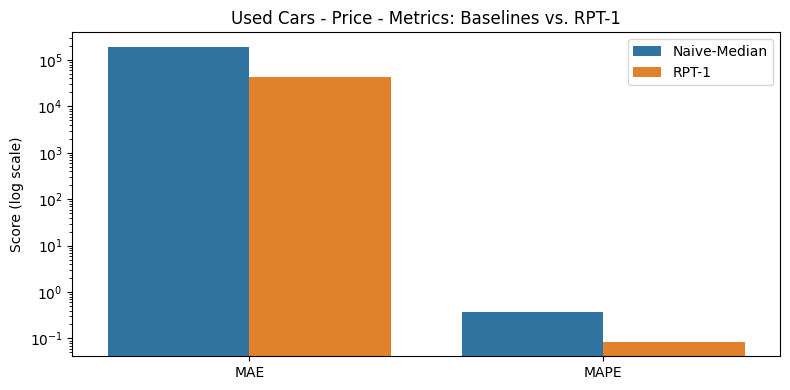

In [23]:
# Prepare long-form for plotting
records = []
for approach, mdict in all_metrics.items():
    for metric, value in mdict.items():
        records.append({"approach": approach, "metric": metric, "value": value})
plot_df = pd.DataFrame(records)

plt.figure(figsize=(8, 4))
sns.barplot(data=plot_df, x="metric", y="value", hue="approach")
plt.title(f"Used Cars - {TARGET_COLUMN} - Metrics: Baselines vs. RPT-1")
plt.ylabel("Score")
plt.xlabel("")
plt.legend(loc="best")

# Use logarithmic scale for regression metrics (large value differences)
if TASK_TYPE == "regression":
    plt.yscale("log")
    plt.ylabel("Score (log scale)")

plt.tight_layout()
plt.show()

In [24]:
## Plot some example predictions 

Text(0.5, 0, 'Values')

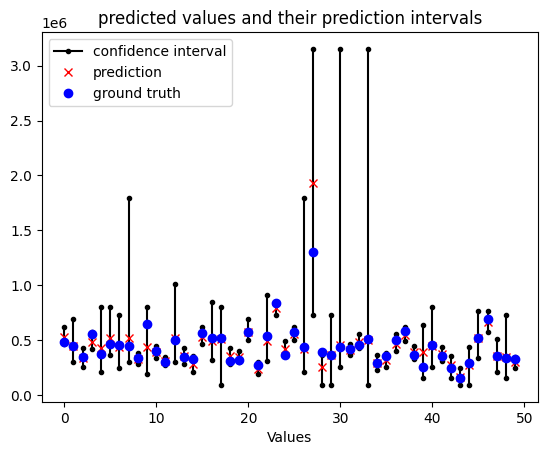

In [25]:
n_test_plot = 50

index_plot = y_pred_rpt.sample(n_test_plot, random_state=0).index

for _cnt, _ix in enumerate(index_plot):
    plt.plot([_cnt, _cnt],[rpt_pred_intervals['lower_bound'][_ix], rpt_pred_intervals['upper_bound'][_ix]], '.-k')
    plt.plot(_cnt, y_pred_rpt[_ix], 'xr')
    plt.plot(_cnt, y_test[_ix], 'ob')

plt.legend(['confidence interval', 'prediction', 'ground truth'])
plt.title('predicted values and their prediction intervals')
plt.xlabel('index')
plt.xlabel('Values')
#


## 12. Follow-up tasks: Evaluate & Iterate
Iterate on target definition, leakage control, split strategy, context selection, and feature set. Further challenges

- Search for outliers (e.g. a car sale where the price was higher than the upper bound of the model predition)
- Explore model explanation explanations features (see also the dummy call above) and identify which features are most important on average
- Enter the details of your own car and get a price estimate of the model